# Comparando los algoritmos

Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

A lo largo de las notebooks anteriores buscamos la gira de **Los Auténticos Descendentes** con cuatro familias de algoritmos de búsqueda local: gradiente descendente, Simulated Annealing, Local Beam y algoritmos genéticos. Cada uno lo probamos por separado y lo comparamos, como mucho, con el anterior.

En esta notebook los ponemos a todos lado a lado, en las mismas condiciones, para sacar algunas conclusiones. Y, de paso, le entregamos al manager los carteles definitivos de las dos versiones de la gira, así puede salir a buscar el presupuesto con los carteles bajo el brazo.

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gira

random.seed(42)

capitals = gira.load_cities("capitales")
distances = gira.distance_matrix(capitals)

cities = gira.load_cities("pueblo_por_pueblo")
city_distances = gira.distance_matrix(cities)

In [2]:
from search_methods import (
    genetic_algorithm,
    gradient_descent,
    local_beam_search,
    simulated_annealing,
    stochastic_local_beam_search,
)

---

## Las reglas de la comparación

Para que la comparación sea justa, cada algoritmo arranca desde giras al azar y lo ejecutamos varias veces, porque todos tienen una parte aleatoria y una sola ejecución puede tener suerte o mala suerte. De cada algoritmo miramos tres cosas:

- **La mejor gira** que encontró en todas las ejecuciones.
- **El costo promedio**, que nos dice qué esperar de una ejecución cualquiera.
- **El tiempo promedio** de cada ejecución.

Usamos los mismos parámetros que en las notebooks anteriores. Gradiente descendente lo ejecutamos con **reinicio aleatorio**, 10 veces desde giras distintas, quedándonos con la mejor: una sola ejecución tarda muy poco y no sería una comparación justa contra algoritmos que tardan segundos.

La siguiente función ejecuta cada algoritmo la cantidad de veces que le pidamos y guarda el costo, el tiempo y la gira de cada ejecución:

In [3]:
def compare_algorithms(algorithms, cities, distances, repetitions):
    """
    Ejecuta varias veces cada algoritmo y guarda el resultado de cada ejecución.

    Args:
        algorithms (dict): Nombre de cada algoritmo y una función que recibe las
                           ciudades y las distancias y devuelve una gira.
        cities (pd.DataFrame): Ciudades de la gira.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        repetitions (int): Cantidad de ejecuciones de cada algoritmo.

    Returns:
        pd.DataFrame: Una fila por ejecución, con el algoritmo, el costo de la gira,
                      el tiempo en segundos y la gira.
    """
    rows = []
    for name, algorithm in algorithms.items():
        for _ in range(repetitions):
            start = time.perf_counter()
            tour = algorithm(cities, distances)
            elapsed = time.perf_counter() - start

            rows.append(
                {
                    "algoritmo": name,
                    "costo": gira.cost_function(tour, distances),
                    "tiempo": elapsed,
                    "gira": tour,
                }
            )
    return pd.DataFrame(rows)


def summarize(results):
    """
    Resume los resultados de compare_algorithms(): la mejor gira, el costo promedio,
    la peor gira y el tiempo promedio de cada algoritmo, ordenados por costo promedio.
    """
    summary = results.groupby("algoritmo", sort=False).agg(
        mejor=("costo", "min"),
        promedio=("costo", "mean"),
        peor=("costo", "max"),
        tiempo=("tiempo", "mean"),
    )
    summary = summary.sort_values("promedio")
    return summary.style.format(
        gira.format_km, subset=["mejor", "promedio", "peor"]
    ).format("{:.2f} s", subset=["tiempo"])

Los algoritmos tienen firmas distintas: algunos reciben una gira, otros una lista de giras. Para poder ejecutarlos a todos de la misma forma, armamos dos funciones auxiliares: una que genera varias giras al azar y otra que hace el reinicio aleatorio de gradiente descendente.

In [4]:
def random_tours(cities, k):
    """Genera k giras al azar."""
    return [gira.init_state(cities) for _ in range(k)]


def restart_gradient_descent(cities, distances, restarts=10):
    """
    Ejecuta gradiente descendente desde varias giras al azar y devuelve la mejor
    gira encontrada.
    """
    best_tour, best_cost = None, np.inf
    for initial_tour in random_tours(cities, restarts):
        tour, history = gradient_descent(initial_tour, distances)
        if history[-1] < best_cost:
            best_tour, best_cost = tour, history[-1]
    return best_tour

---

## La Gira Federal

Empecemos por la gira chica, la de las 24 capitales. Ejecutamos cada algoritmo 10 veces:

In [5]:
federal_algorithms = {
    "Gradiente descendente": restart_gradient_descent,
    "Simulated Annealing": lambda cities, distances: simulated_annealing(
        gira.init_state(cities), distances
    )[0],
    "Local Beam": lambda cities, distances: local_beam_search(
        random_tours(cities, 10), distances
    )[0],
    "Local Beam estocástico": lambda cities, distances: stochastic_local_beam_search(
        random_tours(cities, 10), distances
    )[0],
    "Genético": lambda cities, distances: genetic_algorithm(
        random_tours(cities, 100), distances, max_generations=300
    )[0],
    "Memético": lambda cities, distances: genetic_algorithm(
        random_tours(cities, 50),
        distances,
        max_generations=100,
        improvement_tries=200,
    )[0],
}

federal_results = compare_algorithms(federal_algorithms, capitals, distances, 10)
summarize(federal_results)

,mejor,promedio,peor,tiempo
algoritmo,,,,
Memético,8.402 km,8.402 km,8.402 km,0.97 s
Gradiente descendente,8.402 km,8.407 km,8.418 km,0.02 s
Simulated Annealing,8.402 km,8.410 km,8.450 km,0.11 s
Local Beam estocástico,8.402 km,8.414 km,8.528 km,0.27 s
Genético,8.402 km,8.430 km,8.528 km,0.18 s
Local Beam,8.402 km,8.441 km,8.762 km,0.02 s


Los seis algoritmos encuentran la misma gira de 8.402 km en al menos una de las 10 ejecuciones. Con 24 capitales el problema es lo suficientemente chico como para que hasta el algoritmo más simple llegue: gradiente descendente con reinicio aleatorio la encuentra en un par de centésimas de segundo.

Las diferencias aparecen en el promedio y en la peor gira. El algoritmo memético encuentra los 8.402 km en las 10 ejecuciones, pero tarda casi un segundo en cada una. Local Beam, en cambio, tiene alguna ejecución que se queda en más de 8.700 km.

¿Es 8.402 km la mejor gira posible? No lo sabemos con certeza: para estar seguros habría que revisar las 23! giras posibles, unas 2,6 x 10²². Pero que seis algoritmos distintos, arrancando desde giras al azar, lleguen siempre a la misma gira y ninguno encuentre una mejor es una buena señal de que estamos en el mínimo global, o muy cerca.

---

## La Gira Pueblo por Pueblo

Ahora la gira grande, la de 111 lugares. Como cada ejecución es bastante más cara, ejecutamos cada algoritmo 5 veces. Los parámetros son los mismos que usamos para esta gira en cada notebook:

In [6]:
town_algorithms = {
    "Gradiente descendente": restart_gradient_descent,
    "Simulated Annealing": lambda cities, distances: simulated_annealing(
        gira.init_state(cities),
        distances,
        final_temperature=0.5,
        max_iterations=2_000_000,
    )[0],
    "Local Beam": lambda cities, distances: local_beam_search(
        random_tours(cities, 10), distances
    )[0],
    "Local Beam estocástico": lambda cities, distances: stochastic_local_beam_search(
        random_tours(cities, 10), distances
    )[0],
    "Genético": lambda cities, distances: genetic_algorithm(
        random_tours(cities, 100), distances, max_generations=3_000
    )[0],
    "Memético": lambda cities, distances: genetic_algorithm(
        random_tours(cities, 50),
        distances,
        max_generations=300,
        improvement_tries=1_000,
    )[0],
}

town_results = compare_algorithms(town_algorithms, cities, city_distances, 5)
summarize(town_results)

,mejor,promedio,peor,tiempo
algoritmo,,,,
Simulated Annealing,14.123 km,14.151 km,14.208 km,2.17 s
Memético,14.298 km,14.529 km,14.848 km,14.08 s
Gradiente descendente,14.327 km,14.543 km,14.673 km,1.90 s
Local Beam estocástico,14.450 km,14.634 km,14.975 km,6.52 s
Local Beam,14.392 km,14.924 km,15.615 km,2.84 s
Genético,14.317 km,15.076 km,15.599 km,4.10 s


Veamos cómo se reparten los costos de las 5 ejecuciones de cada algoritmo. La línea punteada marca la gira del cartel que imprimió el manager, la que encontró Simulated Annealing en la notebook 3:

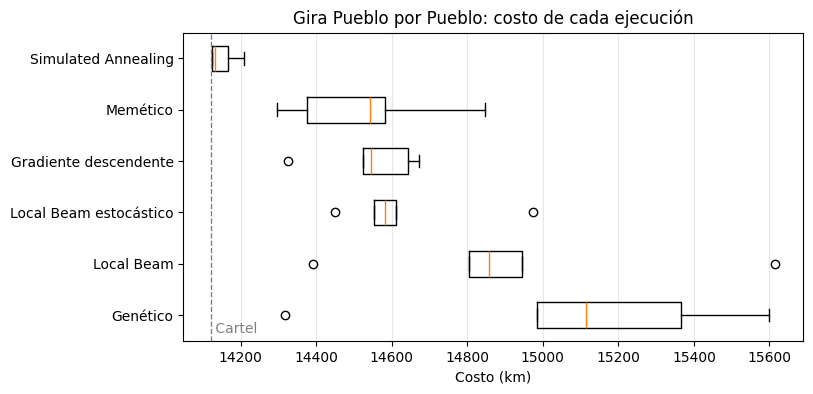

In [7]:
POSTER_KM = 14_123

order = town_results.groupby("algoritmo")["costo"].mean().sort_values().index
costs = [town_results.loc[town_results["algoritmo"] == name, "costo"] for name in order]

plt.figure(figsize=(8, 4))
plt.boxplot(costs, orientation="horizontal", tick_labels=order)
plt.axvline(POSTER_KM, color="gray", linestyle="--", linewidth=1)
plt.text(POSTER_KM, 6.4, " Cartel", color="gray", va="bottom")
plt.gca().invert_yaxis()
plt.xlabel("Costo (km)")
plt.title("Gira Pueblo por Pueblo: costo de cada ejecución")
plt.grid(axis="x", alpha=0.3)
plt.show()

Con 111 lugares las diferencias son claras. Simulated Annealing es el mejor por lejos: su peor ejecución, de 14.208 km, es mejor que la mejor ejecución de cualquier otro algoritmo. Además, su caja es la más angosta del gráfico, así que es también el más consistente.

Gradiente descendente y el algoritmo memético quedan en un segundo grupo, con promedios parecidos. Local Beam y el algoritmo genético puro son los peores en promedio y los más irregulares: el genético tiene una ejecución de 14.317 km y otra de casi 15.600 km.

Simulated Annealing vuelve a llegar a los 14.123 km del cartel. No es la misma gira, porque algunas ciudades están en otro orden, pero tiene la misma longitud. Con tantas ciudades hay muchas giras distintas con costos casi iguales.

El costo no es lo único que importa: también importa cuánto tarda cada algoritmo en encontrar su gira. Pongamos las dos cosas en un mismo gráfico:

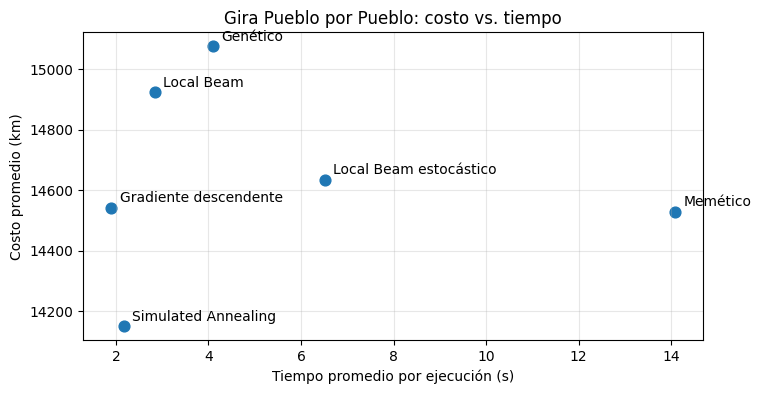

In [8]:
summary = town_results.groupby("algoritmo")[["costo", "tiempo"]].mean()

plt.figure(figsize=(8, 4))
plt.scatter(summary["tiempo"], summary["costo"], s=60)
for name, row in summary.iterrows():
    plt.annotate(
        name, (row["tiempo"], row["costo"]), xytext=(6, 4), textcoords="offset points"
    )
plt.xlabel("Tiempo promedio por ejecución (s)")
plt.ylabel("Costo promedio (km)")
plt.title("Gira Pueblo por Pueblo: costo vs. tiempo")
plt.grid(alpha=0.3)
plt.show()

Lo ideal es estar abajo a la izquierda: giras cortas en poco tiempo. Ahí está Simulated Annealing, que tarda lo mismo que 10 ejecuciones de gradiente descendente y encuentra giras unos 400 km más cortas.

El algoritmo memético necesita unas 7 veces más tiempo que gradiente descendente para llegar a giras parecidas, y Local Beam estocástico tarda más del doble que Local Beam para mejorar unos 300 km en promedio.

> 🧠 **Nota**: Los tiempos dependen de la computadora donde se ejecuta la notebook. Lo que vale la pena mirar es la relación entre los algoritmos, no los segundos exactos.

---

## Conclusiones

**No hay un algoritmo que gane siempre.** En la Gira Federal todos encontraron la misma gira, y el más simple fue el más rápido. Las diferencias aparecieron cuando el problema creció. Ningún algoritmo es el mejor para todos los problemas: Simulated Annealing ganó en este, pero en otro problema el resultado podría ser distinto.

**Lo difícil es escapar de los mínimos locales.** Gradiente descendente y Local Beam se detienen en el primer mínimo que encuentran. Simulated Annealing acepta, de vez en cuando, moverse a una gira peor, y eso es lo que le permite llegar más lejos.

**Buscar con varias giras no alcanza si todas terminan siendo la misma.** Local Beam pierde la diversidad en pocos pasos y termina siendo una única búsqueda. La versión estocástica mejora un poco, a cambio de más tiempo.

**Los operadores tienen que respetar la estructura del problema.** Lo bueno de una gira son sus tramos, y la reproducción por orden los rompe. Por eso el algoritmo genético puro tiene problemas, y el algoritmo memético mejora cuando agrega el movimiento 2-opt. La representación y los vecinos que elegimos en la primera notebook importan tanto como el algoritmo.

**Los resultados dependen de los parámetros.** Usamos los mismos parámetros de las notebooks anteriores y no buscamos los mejores para cada algoritmo. Con más generaciones, otra temperatura o un haz más grande, los resultados podrían cambiar. Toda comparación entre algoritmos vale para el tiempo y los parámetros que usamos.

---

## Los carteles definitivos

Con la comparación terminada, el manager nos pide los carteles de las dos versiones de la gira, cada una con la mejor ruta que encontramos. Primero, la Gira Federal:

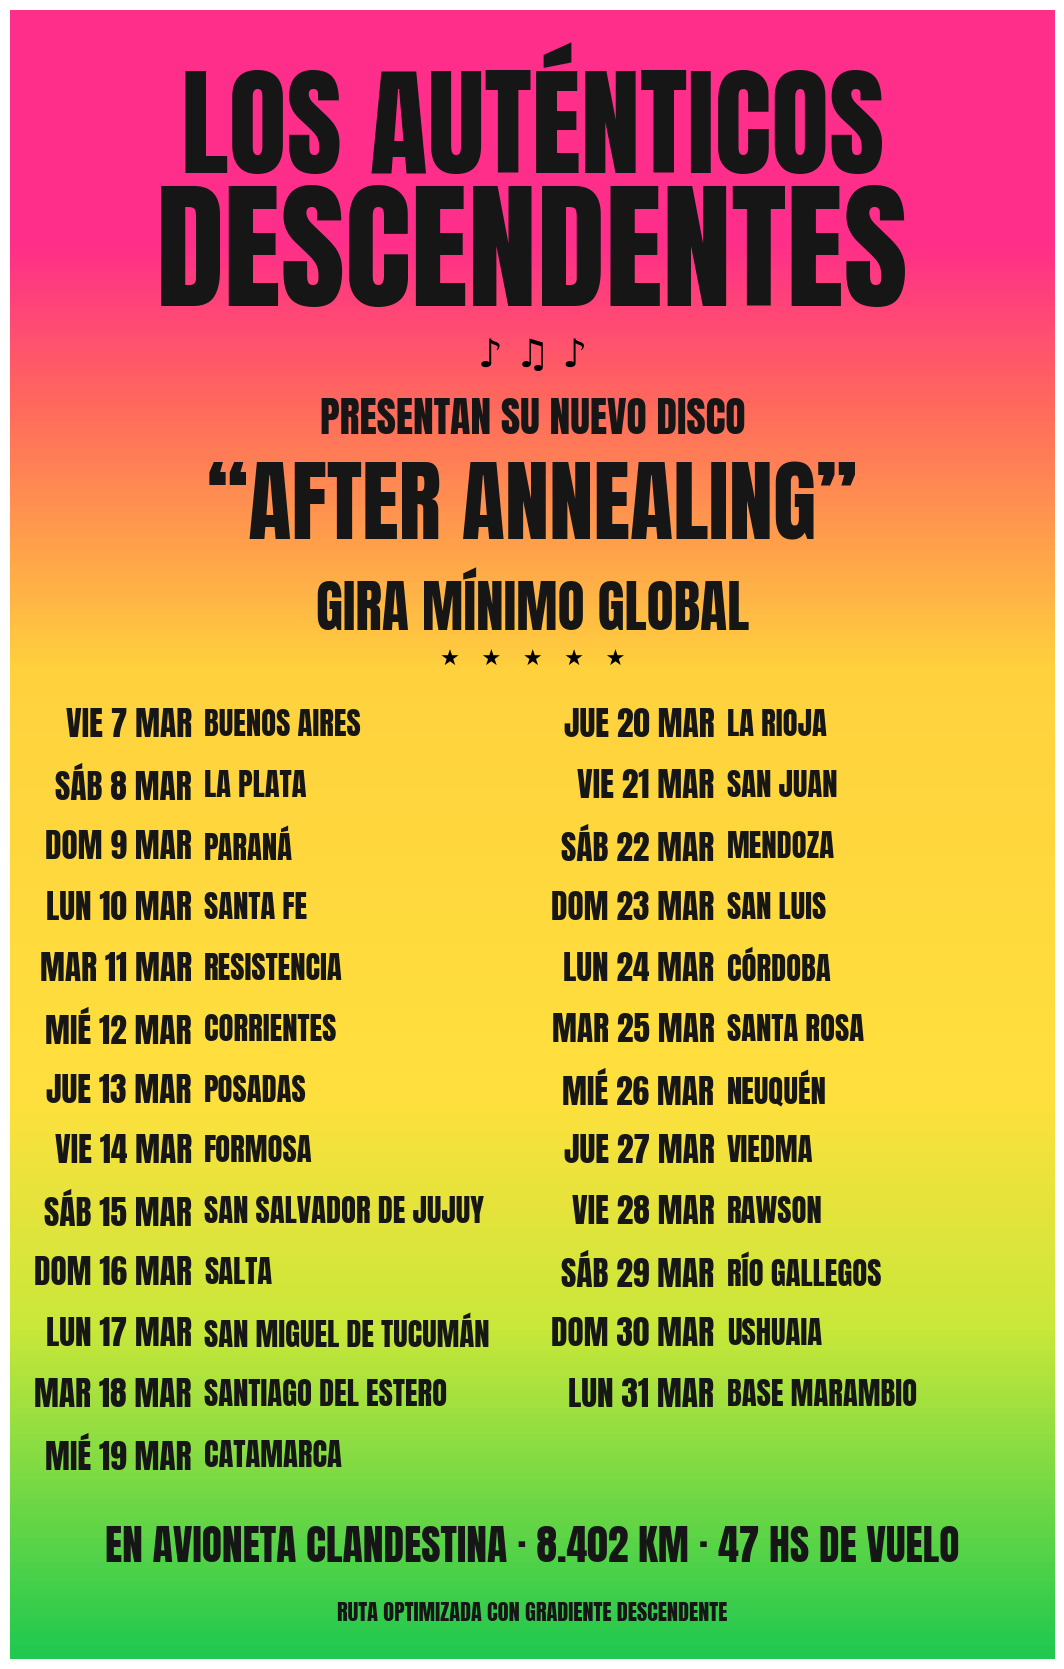

In [9]:
best_federal = federal_results.loc[federal_results["costo"].idxmin()]
gira.plot_poster(
    capitals,
    best_federal["gira"],
    distances,
    footer=f"Ruta optimizada con {best_federal['algoritmo']}",
)

Y la Gira Pueblo por Pueblo:

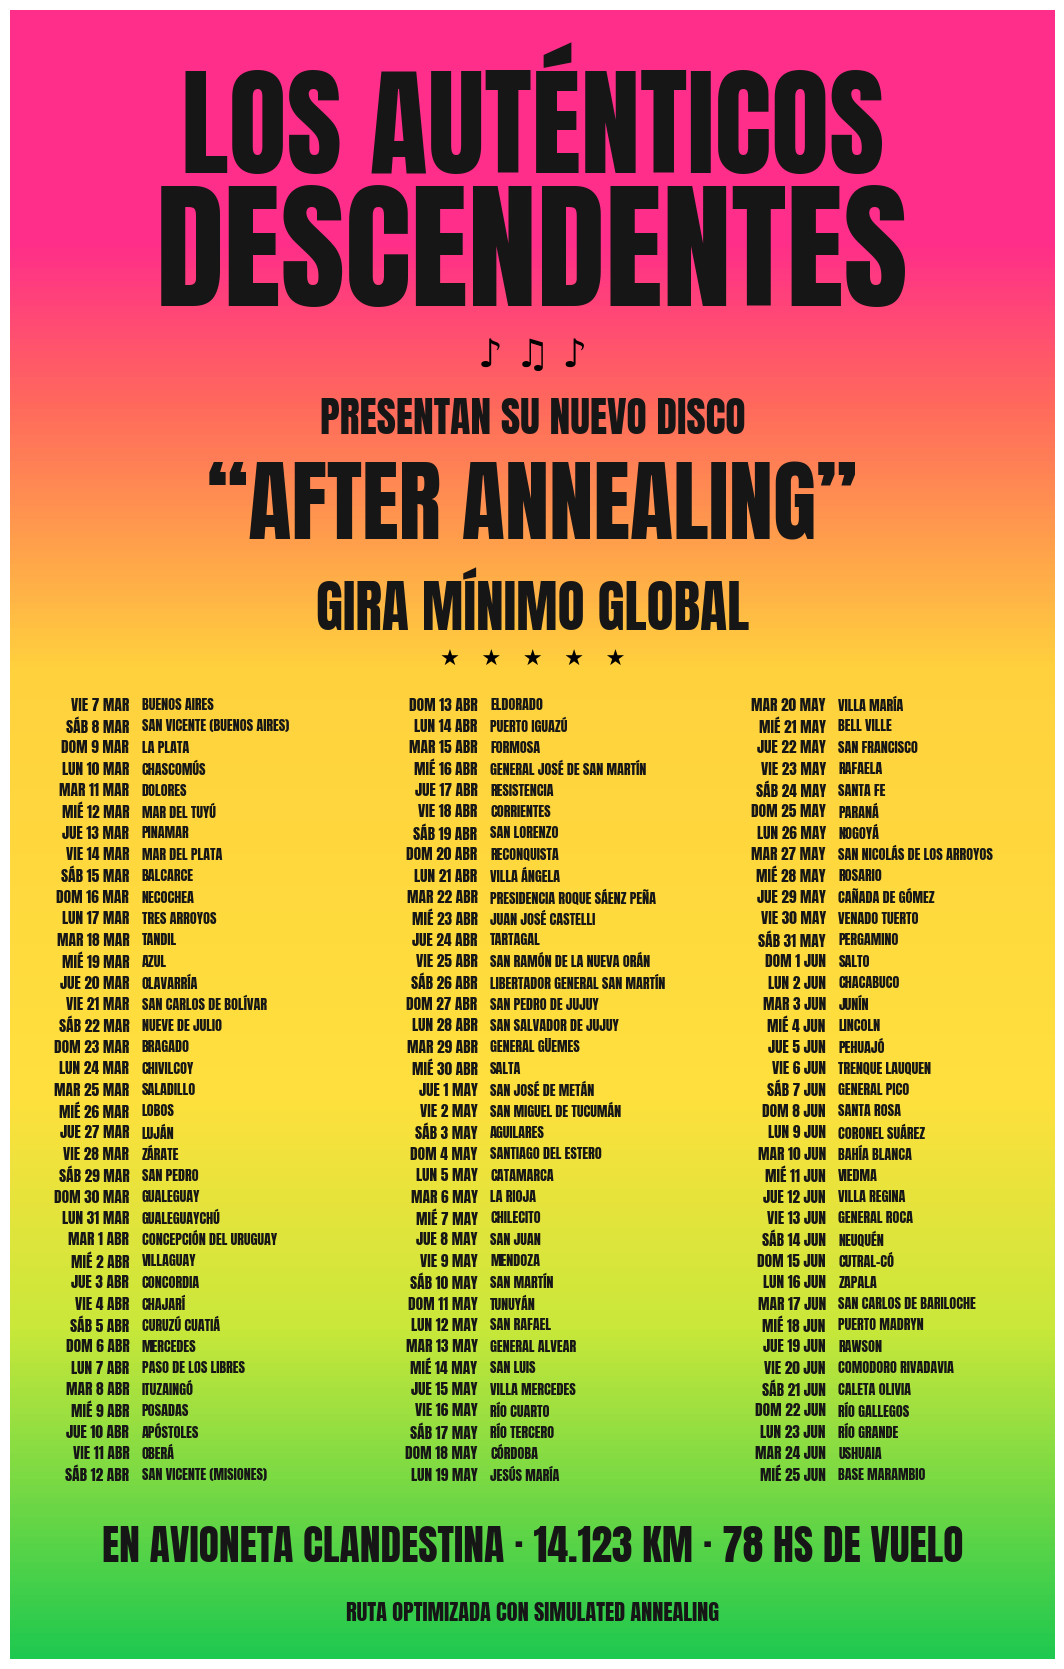

In [10]:
best_town = town_results.loc[town_results["costo"].idxmin()]
gira.plot_poster(
    cities,
    best_town["gira"],
    city_distances,
    footer=f"Ruta optimizada con {best_town['algoritmo']}",
)

El manager pone el cartel nuevo de la Gira Pueblo por Pueblo al lado del que imprimió después de Simulated Annealing y no encuentra la diferencia: los mismos kilómetros, las mismas horas de vuelo y unas pocas ciudades en otro orden. Decide quedarse con el que ya tiene impreso y mandar a imprimir solamente el de la Gira Federal.

Ahora tiene los carteles de las dos versiones de la **Gira Mínimo Global**. Solo le falta conseguir el presupuesto para saber cuál de las dos sale a la ruta, o mejor dicho, al aire.